#Modul Classification: Predict Customer Churn

access the dataset in here: https://www.kaggle.com/datasets/alipakzad/telecom-customer-churn/data

### **Deskripsi Kolom**

| **Nama Kolom** | **Deskripsi** |
| :--- | :--- |
| `customerID` | ID unik untuk setiap pelanggan. |
| `gender` | Jenis kelamin pelanggan (laki-laki atau perempuan). |
| `SeniorCitizen` | Menunjukkan apakah pelanggan termasuk warga lanjut usia (1: Ya, 0: Tidak). |
| `Partner` | Menunjukkan apakah pelanggan memiliki pasangan (Ya, Tidak). |
| `Dependents` | Menunjukkan apakah pelanggan memiliki tanggungan (Ya, Tidak). |
| `tenure` | Jumlah bulan pelanggan telah menggunakan layanan perusahaan. |
| `PhoneService` | Menunjukkan apakah pelanggan menggunakan layanan telepon (Ya, Tidak). |
| `MultipleLines` | Menunjukkan apakah pelanggan memiliki beberapa saluran telepon (Ya, Tidak, Tidak memiliki layanan telepon). |
| `InternetService` | Jenis layanan internet yang digunakan pelanggan (DSL, Fiber Optic, atau Tidak Ada). |
| `OnlineSecurity` | Menunjukkan apakah pelanggan menggunakan layanan keamanan daring (Ya, Tidak, Tidak memiliki layanan internet). |
| `OnlineBackup` | Menunjukkan apakah pelanggan menggunakan layanan pencadangan data daring (Ya, Tidak, Tidak memiliki layanan internet). |
| `DeviceProtection` | Menunjukkan apakah pelanggan menggunakan layanan perlindungan perangkat (Ya, Tidak, Tidak memiliki layanan internet). |
| `TechSupport` | Menunjukkan apakah pelanggan menggunakan layanan dukungan teknis (Ya, Tidak, Tidak memiliki layanan internet). |
| `StreamingTV` | Menunjukkan apakah pelanggan menggunakan layanan streaming TV (Ya, Tidak, Tidak memiliki layanan internet). |
| `StreamingMovies` | Menunjukkan apakah pelanggan menggunakan layanan streaming film (Ya, Tidak, Tidak memiliki layanan internet). |
| `Contract` | Jangka waktu kontrak pelanggan (Bulanan, Satu Tahun, Dua Tahun). |
| `PaperlessBilling` | Menunjukkan apakah pelanggan menggunakan tagihan elektronik tanpa kertas (Ya, Tidak). |
| `PaymentMethod` | Metode pembayaran yang digunakan pelanggan (Cek Elektronik, Cek melalui Pos, Transfer Bank, atau Kartu Kredit). |
| `MonthlyCharges` | Biaya layanan yang dibebankan kepada pelanggan setiap bulan. |
| `TotalCharges` | Total biaya yang telah dibebankan kepada pelanggan. |
| `Churn` | Menunjukkan apakah pelanggan berhenti berlangganan (Ya, Tidak). |

## Import Library

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from imblearn.over_sampling import SMOTE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

import warnings; warnings.filterwarnings("ignore")

## Import Dataset

In [3]:
df = pd.read_csv('/content/IT_customer_churn.csv')

## Data Understanding & Observation

In [4]:
df.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [6]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [7]:
df.duplicated().sum()

np.int64(22)

In [8]:
display(df["OnlineSecurity"].value_counts())

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [9]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [10]:
(df['Churn'].value_counts(normalize=True) * 100).round(2)


,proportion
Churn,
No,73.46
Yes,26.54


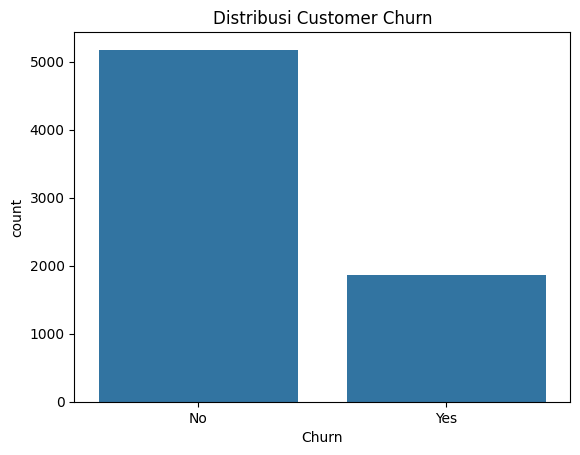

In [11]:
sns.countplot(data=df, x="Churn")
plt.title("Distribusi Customer Churn")
plt.show()

**Temuan awal:**

1. Terdapat `22` kolom yang terdeteksi duplikasi. ini akan dihandling dengan cara di drop/dihapus

2. Banyak kolom yang masih memiliki tipe data `object`. ini perlu di transformasi ke `numeric`

3. `No internet service` bisa di kategorikan atau di mapping sebagai `No`

4. Kelas mengalami imbalance sehingga perlu di handling

5. `TotalCharges` terbaca sebagai teks (`object`) padahal seharusnya angka. Oleh karena itu, perlu dilakukan perbaikan. Namun sebelum itu, ditemukan temuan seperti yang terlihat pada kode dibawah ini.



In [12]:
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
bad = df[tc.isna()]
print("Jumlah TotalCharges tidak valid:", len(bad))
display(bad[["MonthlyCharges", "TotalCharges", "Churn"]])

Jumlah TotalCharges tidak valid: 11


,MonthlyCharges,TotalCharges,Churn
488,52.55,,No
753,20.25,,No
936,80.85,,No
1082,25.75,,No
1340,56.05,,No
3331,19.85,,No
3826,25.35,,No
4380,20.00,,No
5218,19.70,,No
6670,73.35,,No


**Temuan lanjutan:** Setelah dilakukan pemeriksaan lebih lanjut, ditemukan bahwa beberapa nilai pada kolom `TotalCharges` tidak dapat dikonversi menjadi angka. Hal ini terjadi karena nilai tersebut berisi karakter spasi (`" "`), bukan nilai numerik maupun *missing value* (`NaN`) yang terdeteksi oleh `isna()`. Oleh karena itu, pemeriksaan dilakukan dengan mengonversi kolom `TotalCharges` menggunakan `pd.to_numeric()` dengan parameter `errors="coerce"` sehingga nilai yang tidak dapat dikonversi akan diubah menjadi `NaN` pada hasil konversi.



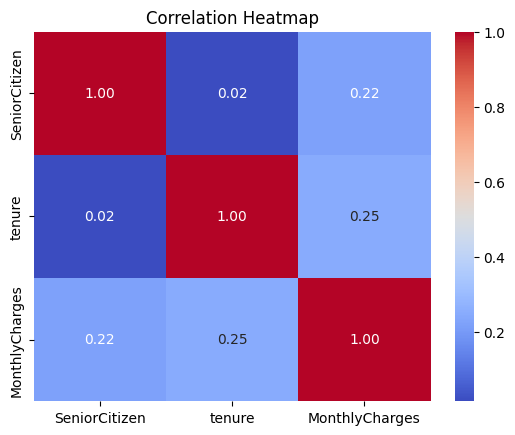

In [13]:
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## Data Cleaning

In [14]:
"""
pertama kita perlu mengubah kolom TotalCharges menjadi tipe numerik. Dengan menggunakan parameter errors="coerce",
nilai yang tidak dapat dikonversi menjadi angka seperti karakter spasi (" ") akan diubah menjadi NaN (Not a Number).
Setelah itu nilai NaN dapat ditangani melalui proses imputasi.
"""
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [15]:
#imputasi menggunakan median (bisa diubah menggunakan metode lain)
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

In [16]:
#lalu cek apakah tipe data TotalCharges sudah berubah/belum
df.dtypes['TotalCharges']

dtype('float64')

In [17]:
#hapus baris yang duplikat
df = df.drop_duplicates()

In [18]:
#mapping target menjadi numeric
df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

In [19]:
#ubah "No internet service" menjadi "No"
df["OnlineSecurity"] = df["OnlineSecurity"].replace("No internet service", "No")

## Splitting

In [20]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### One Hot Encoding

In [22]:
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(include="object").columns

In [23]:
encoder = OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False)

X_train_cat = pd.DataFrame(encoder.fit_transform(X_train[cat_cols]), columns=encoder.get_feature_names_out(cat_cols), index=X_train.index)
X_test_cat = pd.DataFrame(encoder.transform(X_test[cat_cols]), columns=encoder.get_feature_names_out(cat_cols), index=X_test.index)

X_train = pd.concat([X_train[num_cols], X_train_cat], axis=1)
X_test = pd.concat([X_test[num_cols], X_test_cat], axis=1)

In [24]:
#lihat setelah dilakukan encoding
X_train.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
2629,0,2,70.70,140.70,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2650,0,15,84.35,1302.65,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1418,0,67,89.55,6373.10,1.0,1.0,1.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5774,0,5,65.60,339.90,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
2425,0,26,20.30,511.25,1.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


### Scaling

In [25]:
#melakukan scaling karena akan apply model KNN
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## Handling Imbalance (Oversampling)

In [26]:
# periksa distribusi kelas sebelum dilakukan oversampling
print("Sebelum oversampling:")
print(y_train.value_counts())

Sebelum oversampling:
Churn
0    4131
1    1485
Name: count, dtype: int64


In [27]:
smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(X_train, y_train)

In [28]:
print("\nSetelah oversampling:")
print(y_train.value_counts())


Setelah oversampling:
Churn
1    4131
0    4131
Name: count, dtype: int64


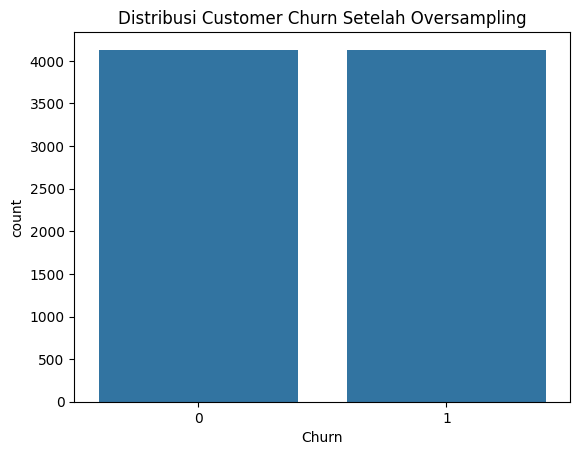

In [29]:
sns.countplot(data=df, x=y_train)
plt.title("Distribusi Customer Churn Setelah Oversampling")
plt.show()

## Modelling

Untuk memahami beberapa pendekatan dalam klasifikasi, disini kita menggunakan 3 algoritma yaitu:

| Algoritma | Pendekatan | Gambaran Umum |
|---|---|---|
| K-Nearest Neighbors (KNN) | Distance-based | Memprediksi kelas berdasarkan tetangga terdekat. |
| Decision Tree | Tree-based | Membentuk aturan keputusan berdasarkan fitur data. |
| Random Forest | Bagging | Menggabungkan prediksi dari banyak decision tree. |

### 1. K-Nearest Neighbors (KNN)
K-Nearest Neighbors (KNN) adalah algoritma *supervised learning* yang dapat digunakan untuk klasifikasi maupun regresi. Pada tugas klasifikasi, KNN menentukan kelas suatu data berdasarkan kelas mayoritas dari sejumlah tetangga terdekatnya.

KNN termasuk algoritma berbasis jarak (*distance-based*) karena menentukan kedekatan antar data menggunakan perhitungan jarak.

Pada dataset **customer churn classification** ini, KNN digunakan untuk memprediksi apakah pelanggan akan berhenti berlangganan (`Churn = Yes`) atau tetap berlangganan (`Churn = No`).

Intuisi dasarnya adalah pelanggan yang memiliki karakteristik serupa cenderung mempunyai perilaku yang serupa pula. Sebagai contoh, pelanggan baru dengan lama berlangganan, biaya bulanan, dan jenis kontrak yang mirip dengan pelanggan yang pernah churn mungkin memiliki risiko churn yang serupa.

Namun, kemiripan karakteristik tidak menjamin perilaku yang sama. KNN menggunakan pola dari data training untuk menentukan prediksi.

#### **Cara Kerja**

![Ilustrasi algoritma K-Nearest Neighbors (KNN)](https://miro.medium.com/v2/resize:fit:1182/0*6B5fQur1C0IXZ7jK.png)


KNN bekerja melalui empat langkah berikut:

1. **Menentukan nilai k** — memilih jumlah tetangga terdekat yang akan digunakan.
2. **Menghitung jarak** — menghitung jarak antara data yang akan diprediksi dengan setiap data training.
3. **Memilih tetangga terdekat** — mengambil sebanyak k data dengan jarak terkecil.
4. **Menentukan kelas** — memilih kelas yang paling banyak muncul di antara tetangga tersebut.

Sebagai contoh, misalkan kita menggunakan `k = 5`. Dari lima pelanggan terdekat, tiga pelanggan memiliki status churn `Yes` dan dua lainnya memiliki status churn `No`.

Karena kelas `Yes` merupakan mayoritas, model akan memprediksi bahwa pelanggan baru tersebut berpotensi churn.

#### **Konsep Jarak pada KNN**

Salah satu metode yang umum digunakan untuk menghitung jarak adalah *Euclidean Distance*. Rumusnya adalah:

$$
d(x,y) = \sqrt{\sum_{i=1}^{n}(x_i-y_i)^2}
$$

Keterangan:

- \(d(x,y)\): jarak antara dua data.
- \(x_i\): nilai fitur ke-\(i\) dari data pertama.
- \(y_i\): nilai fitur ke-\(i\) dari data kedua.
- \(n\): jumlah fitur yang digunakan dalam perhitungan.

Semakin kecil jarak antara dua data, semakin dekat karakteristik kedua data tersebut berdasarkan fitur yang digunakan.

Pada dataset customer churn, fitur seperti `tenure` dan `MonthlyCharges` memiliki skala yang berbeda. Oleh karena itu, *scaling* diperlukan agar fitur dengan rentang angka yang besar tidak mendominasi perhitungan jarak.


In [30]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

### 2. Decision Tree

Decision Tree adalah algoritma *supervised learning* yang dapat digunakan untuk klasifikasi maupun regresi. Algoritma ini bekerja dengan membagi data berdasarkan kondisi tertentu hingga menghasilkan keputusan atau prediksi.

Decision Tree memiliki struktur menyerupai pohon yang terdiri dari *root node* (simpul awal), *decision node* (simpul keputusan), *branch* (cabang), dan *leaf node* (simpul akhir yang menghasilkan prediksi).

#### **Cara Kerja**

![Ilustrasi algoritma Decision Tree](https://miro.medium.com/v2/resize:fit:1200/1*TiB4AGb_hQ6W4JkELjvCbQ.png)

Decision Tree bekerja melalui empat langkah berikut:

1. **Memilih fitur** — menentukan fitur yang paling baik untuk membagi data berdasarkan kriteria tertentu.
2. **Membagi data** — memisahkan data ke dalam kelompok berdasarkan kondisi pada fitur terpilih.
3. **Mengulangi proses pembagian** — membuat cabang dan mencari pembagian berikutnya pada setiap kelompok data.
4. **Menentukan kelas** — menghasilkan prediksi berdasarkan kelas mayoritas pada *leaf node* tempat data berakhir.

Sebagai contoh, model dapat membuat aturan berdasarkan `tenure`. Jika pelanggan memiliki masa berlangganan yang pendek, model akan mengikuti cabang tertentu. Selanjutnya, model dapat mempertimbangkan fitur lain, seperti `Contract`, untuk menentukan prediksi akhir.

#### **Konsep Pemilihan Fitur**

Decision Tree perlu menentukan fitur dan kondisi pembagian yang paling baik pada setiap simpul. Salah satu kriteria yang umum digunakan adalah *Gini Impurity*.

Gini Impurity mengukur tingkat ketidakmurnian kelas dalam suatu kelompok data. Rumusnya adalah:

$$
Gini = 1 - \sum_{i=1}^{C} p_i^2
$$

Keterangan:

- \(C\): jumlah kelas.
- \(p_i\): proporsi data yang termasuk kelas ke-\(i\).

Nilai Gini yang lebih rendah menunjukkan bahwa suatu kelompok data lebih didominasi oleh satu kelas. Sebaliknya, nilai yang lebih tinggi menunjukkan bahwa kelompok tersebut memiliki campuran kelas yang lebih beragam.

Dalam proses pembagian data, Decision Tree berusaha menemukan pemisahan yang dapat mengurangi ketidakmurnian kelompok data.


In [31]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

### 3. Random Forest

Random Forest adalah algoritma *supervised learning* yang dapat digunakan untuk klasifikasi maupun regresi. Algoritma ini termasuk metode *ensemble learning*, yaitu pendekatan yang menggabungkan beberapa model untuk menghasilkan prediksi yang lebih baik.

Random Forest merupakan pengembangan dari Decision Tree. Jika Decision Tree menggunakan satu pohon keputusan untuk menghasilkan prediksi, Random Forest menggabungkan prediksi dari banyak pohon keputusan.

#### **Cara Kerja**

![Ilustrasi algoritma Random Forest](https://miro.medium.com/v2/1*hmtbIgxoflflJqMJ_UHwXw.jpeg)


Random Forest bekerja melalui empat langkah berikut:

1. **Mengambil sampel data** — membuat beberapa sampel dari data training menggunakan teknik *bootstrap sampling*.
2. **Membangun decision tree** — melatih setiap pohon menggunakan sampel data yang diperoleh, dengan mempertimbangkan subset fitur secara acak pada proses pembagian simpul.
3. **Menggabungkan prediksi** — mengumpulkan hasil prediksi dari seluruh pohon yang telah dibangun.
4. **Menentukan kelas akhir** — memilih kelas berdasarkan suara mayoritas dari seluruh pohon untuk tugas klasifikasi.

Sebagai contoh, misalkan Random Forest menggunakan 100 pohon keputusan. Jika 75 pohon memprediksi `Churn = Yes` dan 25 pohon memprediksi `Churn = No`, kelas akhir yang diprediksi adalah `Yes`.

In [32]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)


## Evaluation Metrics

Setelah model dilatih, kita perlu melihat seberapa baik model dalam memprediksi data yang belum pernah dilihat sebelumnya. Pada kasus ini, model digunakan untuk memprediksi apakah pelanggan akan berhenti berlangganan (*customer churn*).

Target yang digunakan terdiri dari dua kelas:

- **Kelas 0:** Pelanggan tidak churn.
- **Kelas 1:** Pelanggan churn.

Untuk mengevaluasi model, kita menggunakan beberapa metrik dari `classification_report()`.

### **1. Precision**

Precision mengukur proporsi prediksi positif yang benar-benar positif.

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

Pada prediksi churn, precision menunjukkan seberapa banyak pelanggan yang diprediksi churn ternyata memang churn. Semakin tinggi nilainya, semakin sedikit prediksi churn yang salah.

### **2. Recall**

Recall mengukur proporsi data positif aktual yang berhasil dikenali oleh model.

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

Pada kasus ini, recall menunjukkan seberapa banyak pelanggan yang benar-benar churn berhasil ditemukan oleh model. Jika recall rendah, berarti masih banyak pelanggan yang sebenarnya churn tetapi tidak terdeteksi.

### **3. F1-Score**

F1-score menggabungkan precision dan recall menggunakan rata-rata harmonik.

$$
F_1 = 2 \times
\frac{\text{Precision} \times \text{Recall}}
{\text{Precision} + \text{Recall}}
$$

Metrik ini membantu kita melihat keseimbangan antara precision dan recall. Nilai F1-score yang tinggi menunjukkan keseimbangan yang lebih baik antara kedua metrik tersebut.

### **4. Support**

Support menunjukkan jumlah data aktual pada setiap kelas dalam data pengujian.

Pada dataset ini:

- Kelas 0 memiliki 1.033 data.
- Kelas 1 memiliki 372 data.
- Total data pengujian adalah 1.405 data.

Support bukan ukuran performa model, melainkan jumlah sampel yang digunakan untuk menghitung metrik pada setiap kelas.

### **5. Accuracy**

Accuracy mengukur proporsi seluruh prediksi yang benar terhadap jumlah seluruh data.

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

Berdasarkan hasil pengujian, accuracy KNN adalah 76%, Decision Tree 72%, dan Random Forest 77%. Dengan demikian, Random Forest memiliki accuracy tertinggi di antara ketiga model.

Namun, accuracy saja belum cukup untuk menentukan model terbaik karena model juga perlu dievaluasi berdasarkan kemampuannya mengenali pelanggan yang churn.

### **6. Macro Average**

Macro average menghitung rata-rata suatu metrik dari seluruh kelas dengan bobot yang sama.

Sebagai contoh, macro F1-score untuk dua kelas dihitung menggunakan rumus:

$$
\text{Macro F1} = \frac{F_{1,0} + F_{1,1}}{2}
$$

Setiap kelas memiliki bobot yang sama, terlepas dari jumlah datanya. Metrik ini membantu kita mengevaluasi performa model pada kedua kelas secara seimbang.

### **7. Weighted Average**

Weighted average menghitung rata-rata suatu metrik dengan mempertimbangkan jumlah data pada setiap kelas.

$$
\text{Weighted Average} =
\frac{\sum_{i=1}^{C} n_i s_i}
{\sum_{i=1}^{C} n_i}
$$

Keterangan:

- $C$ = jumlah kelas.
- $n_i$ = jumlah data (*support*) pada kelas ke-$i$.
- $s_i$ = nilai metrik pada kelas ke-$i$.

Kelas yang memiliki lebih banyak data akan memberikan pengaruh lebih besar terhadap nilai akhirnya. Pada dataset ini, kelas 0 memiliki jumlah data lebih banyak daripada kelas 1. Karena itu, weighted average lebih banyak dipengaruhi oleh hasil prediksi pada kelas 0.

In [33]:
#1. KNN
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.87      0.68      0.76      1033
           1       0.45      0.72      0.55       372

    accuracy                           0.69      1405
   macro avg       0.66      0.70      0.66      1405
weighted avg       0.76      0.69      0.71      1405



In [34]:
#2. Decision Tree
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.83      0.80      0.82      1033
           1       0.50      0.55      0.52       372

    accuracy                           0.73      1405
   macro avg       0.66      0.68      0.67      1405
weighted avg       0.74      0.73      0.74      1405



In [35]:
#3. Random Forest
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1033
           1       0.59      0.54      0.57       372

    accuracy                           0.78      1405
   macro avg       0.71      0.70      0.71      1405
weighted avg       0.77      0.78      0.78      1405



### Confusion Matrix

*Confusion matrix* adalah tabel yang digunakan untuk mengevaluasi performa model klasifikasi dengan membandingkan hasil prediksi model terhadap label sebenarnya. Confusion matrix terdiri dari empat komponen:

![Confusion Matrix](https://www.mygreatlearning.com/blog/wp-content/uploads/2020/03/confusion0-matrix-viosualtion-1024x661.webp)


| Komponen | Penjelasan |
|---|---|
| **True Negative (TN)** | Pelanggan tidak churn dan diprediksi tidak churn. |
| **False Positive (FP)** | Pelanggan tidak churn, tetapi diprediksi churn. |
| **False Negative (FN)** | Pelanggan churn, tetapi diprediksi tidak churn. |
| **True Positive (TP)** | Pelanggan churn dan diprediksi churn. |


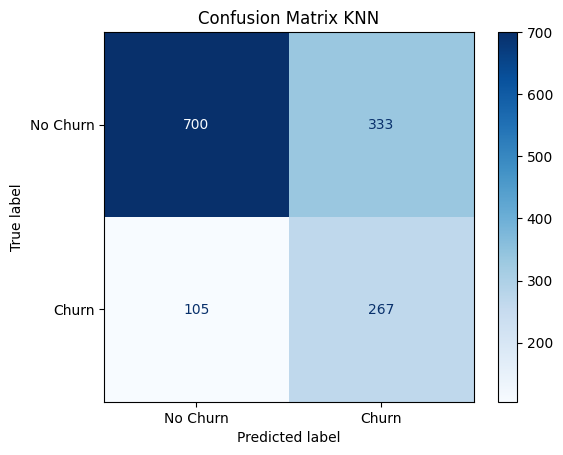

In [36]:
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Confusion Matrix KNN")
plt.show()

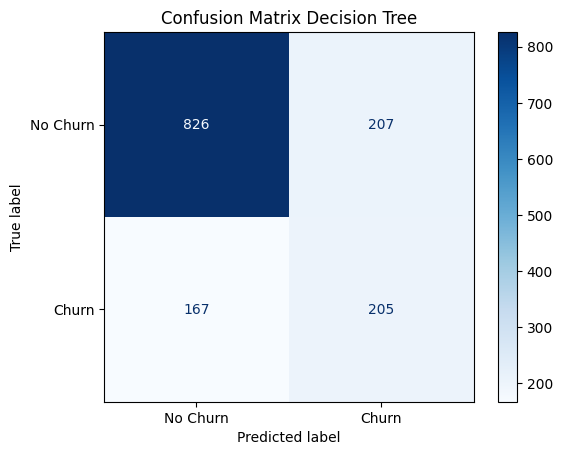

In [37]:
ConfusionMatrixDisplay.from_estimator(dt, X_test, y_test, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Confusion Matrix Decision Tree")
plt.show()

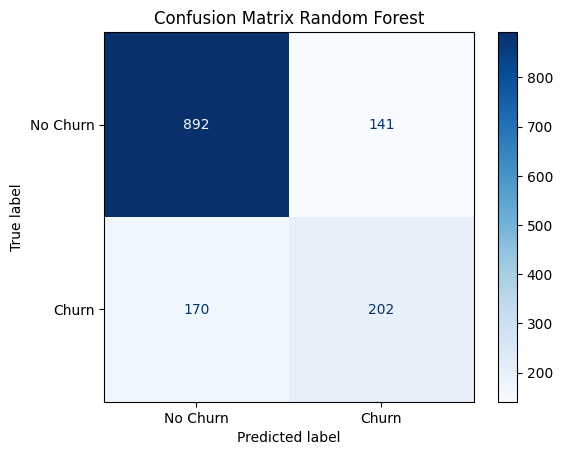

In [38]:
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, display_labels=["No Churn", "Churn"], cmap="Blues")
plt.title("Confusion Matrix Random Forest")
plt.show()

## Feature Importance

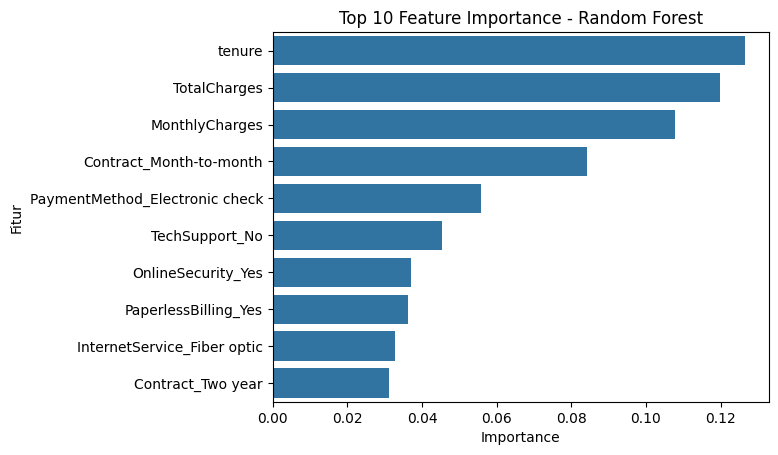

In [39]:
importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

sns.barplot(x=importance.values, y=importance.index)
plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.show()

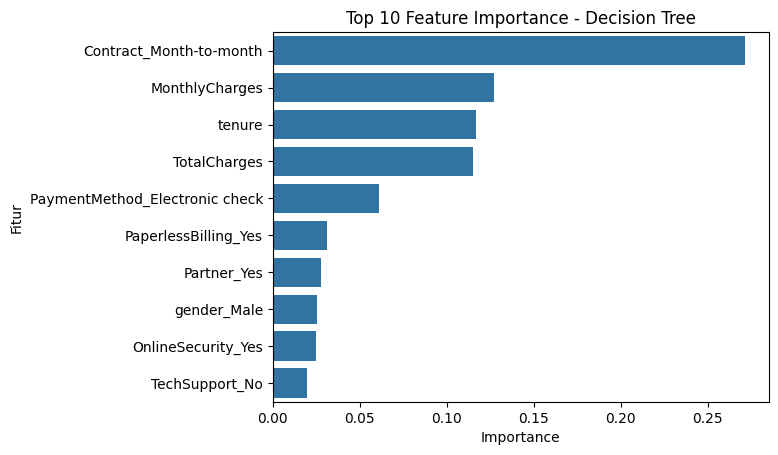

In [40]:
importance = pd.Series(dt.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

sns.barplot(x=importance.values, y=importance.index)
plt.title("Top 10 Feature Importance - Decision Tree")
plt.xlabel("Importance")
plt.ylabel("Fitur")
plt.show()